# Projet F7 — Détection d'anomalies sur le S&P 500 avec Isolation Forest
## Anomalies de marché et politique monétaire de la Réserve fédérale (Fed)

**Machine Learning appliqué à la Finance — ENCG — 4ᵉ année Finance**

---
### 2. Identité et sujet attribué
| | |
|---|---|
| Nom et prénom | *À compléter* |
| Code Apogée | *À compléter* |
| Groupe | *À compléter* |
| Sujet | **F7 — Détection d'anomalies sur le S&P 500** |
| Algorithme imposé | **Isolation Forest (n°24)** |

> **Mode d'emploi (Google Colab)** : *Exécution → Tout exécuter*. Les données sont téléchargées automatiquement depuis FRED (Federal Reserve Bank of St. Louis). Si le téléchargement échoue, la cellule de chargement vous demandera de téléverser les fichiers CSV.

## 3. Introduction et contexte financier

**S&P 500.** Indice boursier pondéré par les capitalisations flottantes des ~500 plus grandes sociétés cotées aux États-Unis. C'est la référence du marché actions américain.

**Taux directeur de la Fed.** Le *federal funds rate* est le taux auquel les banques se prêtent des réserves à un jour. Le FOMC en fixe une **fourchette cible** (ex. 4,25–4,50 %). Il influence le coût du crédit, les taux obligataires, et donc la valorisation des actions (actualisation des flux futurs).

**Anomalie financière.** Observation dont le comportement (rendement, volatilité, perte cumulée…) s'écarte fortement de l'ensemble des observations « habituelles ». Une anomalie *statistique* n'est pas forcément une crise, ni une erreur de données.

**Lien Fed ↔ actions (deux sens possibles).**
1. *Fed → marché* : une décision ou un signal de politique monétaire provoque un choc sur les actions.
2. *Marché → Fed* : un stress de marché majeur pousse la Fed à réagir (baisse d'urgence de mars 2020, par exemple).

Ces deux canaux peuvent coexister, et un troisième facteur (inflation, pandémie…) peut agir sur les deux : **le projet mesure des associations temporelles, pas une causalité.**

## 4. Problématique et objectif

> **Problématique.** *Dans quelle mesure les comportements atypiques du S&P 500 détectés par Isolation Forest sont-ils associés aux variations du taux directeur de la Réserve fédérale américaine : les anomalies précèdent-elles les décisions de la Fed (réaction à un stress de marché) ou les suivent-elles (choc de politique monétaire) ?*

**Objectif mesurable.** Sur l'historique disponible :
1. Détecter les jours atypiques du S&P 500 avec Isolation Forest, entraîné **uniquement sur la période chronologiquement la plus ancienne**.
2. Mesurer si la fréquence d'anomalies est **plus élevée autour des dates de changement de la fourchette cible** que ce qu'on attendrait par hasard (test de permutation).
3. Mesurer si, après le **début d'un épisode d'anomalies**, la probabilité d'un changement de taux dans les 60 jours est supérieure à sa fréquence de base.
4. Confronter les résultats à des événements Fed **documentés par des sources officielles**.

**Hypothèses.**
- H0 : la position des anomalies par rapport aux décisions de la Fed est indistinguable du hasard.
- H1 : les anomalies sont significativement plus fréquentes autour des décisions (ou avant elles).

*Remarque honnête* : les changements de taux sont rares (quelques dizaines sur 10 ans) et les anomalies sont groupées dans le temps ; la puissance statistique est donc faible et les conclusions doivent rester prudentes.

## 5. Présentation du dataset

| Série | Identifiant FRED | Contenu | Fréquence |
|---|---|---|---|
| S&P 500 | `SP500` | Niveau de clôture de l'indice (S&P Dow Jones Indices LLC, via FRED) | Quotidienne (jours de bourse) |
| Taux cible Fed (borne haute) | `DFEDTARU` | Borne supérieure de la fourchette cible du federal funds rate | Quotidienne (calendaire) |
| Taux effectif | `DFF` | Federal funds effective rate | Quotidienne (calendaire) |

**Provenance.** Le notebook fourni par l'enseignant (`djia-sp500-daily-data.ipynb`) télécharge la série `SP500` depuis FRED ; ce projet reprend la **même série** et supprime les séries Dow Jones (DJIA, DJTA, DJCA, DJUA), hors sujet. Les séries `DFEDTARU` et `DFF` proviennent du même site FRED. Aucune licence ni date d'extraction n'est affirmée ici : la date de téléchargement est affichée à l'exécution.

**Choix à justifier à l'oral.** `SOURCE = "fred"` récupère l'historique complet disponible (≈10 ans) car le fichier `SP500.csv` joint (≈1 an) contient trop peu de changements de taux pour la problématique. Mettre `SOURCE = "csv"` pour travailler uniquement sur ce fichier.

**Limite connue.** `SP500` n'a pas de colonnes Open/High/Low/Volume : amplitude journalière et variation de volume ne sont **pas** calculables et ne sont donc pas utilisées.

## 6. Dictionnaire des variables

| Variable | Signification financière | Rôle | Type | Unité | Manquants |
|---|---|---|---|---|---|
| `close` (`SP500`) | Niveau de clôture de l'indice | Base de tous les calculs | Numérique continu | Points d'indice | NaN les jours fériés (supprimés) |
| `ret` | Rendement logarithmique journalier | Feature — choc quotidien | Numérique continu | Sans unité (×100 = %) | 1ʳᵉ ligne |
| `vol20` | Volatilité réalisée sur 20 jours, annualisée | Feature — régime de risque | Numérique continu | % annualisé | 20 premières lignes |
| `ret5` | Rendement cumulé sur 5 jours | Feature — mouvements persistants | Numérique continu | Sans unité | 5 premières lignes |
| `dd60` | Drawdown vs plus haut des 60 derniers jours | Feature — pertes cumulées | Numérique continu (≤ 0) | Sans unité | 59 premières lignes |
| `DFEDTARU` | Borne haute de la fourchette cible Fed | Variable externe (non utilisée par le modèle) | Numérique | % | Aucun après propagation |

## 7. Importation des bibliothèques

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Paramètres généraux --------------------------------------------------
SOURCE = "fred"          # "fred" = historique complet FRED | "csv" = fichier SP500.csv fourni (≈ 1 an)
START  = "2013-11-15"    # même date de début que le notebook de l'enseignant (FRED limite l'historique à ~10 ans)
WINDOW_K = 5             # demi-fenêtre (jours de bourse) autour d'une décision de la Fed
HORIZON_DAYS = 60        # horizon (jours calendaires) pour la réaction de la Fed après une anomalie

NAVY, BLUE, LIGHT, RED = "#0B2545", "#1F6FEB", "#8DA9C4", "#D62828"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "font.size": 10})
os.makedirs("figures", exist_ok=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
print("Bibliothèques chargées | random_state =", RANDOM_STATE)

Bibliothèques chargées | random_state = 42


## 8. Chargement des données

In [3]:
RAW = Path("data/raw")

def _read(path):
    """Lit un CSV FRED (colonne 1 = date, colonne 2 = valeur ; FRED note '.' les valeurs absentes)."""
    df = pd.read_csv(path)
    col = df.columns[1]
    df.columns = ["date", col]
    df["date"] = pd.to_datetime(df["date"])
    df[col] = pd.to_numeric(df[col], errors="coerce")
    return df.set_index("date").sort_index()

def get_series(sid):
    path = RAW / f"{sid}.csv"
    if SOURCE == "csv" and sid == "SP500" and Path("SP500.csv").exists():
        print(f"{sid}: lu depuis le fichier SP500.csv fourni")
        return _read("SP500.csv")
    try:
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd={START}"
        pd.read_csv(url).to_csv(path, index=False)        # copie locale (→ data/raw/)
        print(f"{sid}: téléchargé depuis FRED le {pd.Timestamp.today():%Y-%m-%d}")
        return _read(path)
    except Exception as e:
        if path.exists():
            print(f"{sid}: FRED inaccessible ({type(e).__name__}) → copie locale {path}")
            return _read(path)
        try:                                               # secours Google Colab : téléversement manuel
            from google.colab import files
            print(f"FRED inaccessible. Téléversez le fichier {sid}.csv (export FRED de la série {sid}).")
            up = files.upload()
            Path(list(up)[0]).replace(path)
            return _read(path)
        except ImportError:
            raise RuntimeError(f"Impossible de charger {sid}: placez {sid}.csv dans data/raw/")

sp      = get_series("SP500")
fed_up  = get_series("DFEDTARU")
fed_eff = get_series("DFF")
print("\nS&P 500 brut :", sp.shape, "| Taux cible :", fed_up.shape, "| Taux effectif :", fed_eff.shape)
sp.head()

SP500: téléchargé depuis FRED le 2026-11-18
DFEDTARU: téléchargé depuis FRED le 2026-11-18
DFF: téléchargé depuis FRED le 2026-11-18

S&P 500 brut : (261, 1) | Taux cible : (4751, 1) | Taux effectif : (4750, 1)


,SP500
date,
2025-11-17,6672.41
2025-11-18,6617.32
2025-11-19,6642.16
2025-11-20,6538.76
2025-11-21,6602.99


## 9. Inspection de la qualité

On vérifie structure, valeurs manquantes, doublons et valeurs extrêmes. **Les valeurs extrêmes ne sont pas supprimées** : dans un projet de détection d'anomalies, elles sont précisément le phénomène recherché.

In [4]:
print("=== A. Structure (S&P 500 brut) ===")
print("Lignes, colonnes     :", sp.shape)
print("Types                :", dict(sp.dtypes.astype(str)))
print("Période              :", sp.index.min().date(), "→", sp.index.max().date())
print("Valeurs manquantes   :", int(sp['SP500'].isna().sum()), "(jours fériés notés '.' par FRED)")
print("Doublons de dates    :", int(sp.index.duplicated().sum()))

px = sp["SP500"].dropna()     # jours fériés sans cotation : rien à imputer, ce ne sont pas des observations de marché
gaps = px.index.to_series().diff().dt.days
print("\n=== B. Fréquence (après suppression des jours sans cotation) ===")
print("Observations utiles  :", len(px))
print("Écart médian         :", gaps.median(), "jour(s) | écart max :", int(gaps.max()), "jours")
print("Écarts > 5 jours     :", int((gaps > 5).sum()))

print("\n=== C. Cohérence ===")
print("Valeurs <= 0         :", int((px <= 0).sum()))
r = px.pct_change().dropna()
print("Rendement min / max  : {:.2%} / {:.2%}".format(r.min(), r.max()))
print("\n5 plus fortes variations journalières (CONSERVÉES) :")
display(r.reindex(r.abs().nlargest(5).index).to_frame("rendement").style.format("{:.2%}"))

print("=== D. Séries Fed ===")
for name, s in [("DFEDTARU", fed_up["DFEDTARU"]), ("DFF", fed_eff["DFF"])]:
    print(f"{name}: {s.index.min().date()} → {s.index.max().date()} | manquants = {int(s.isna().sum())} | min/max = {s.min():.2f}/{s.max():.2f} %")

=== A. Structure (S&P 500 brut) ===
Lignes, colonnes     : (261, 1)
Types                : {'SP500': 'float64'}
Période              : 2025-11-17 → 2026-11-16
Valeurs manquantes   : 10 (jours fériés notés '.' par FRED)
Doublons de dates    : 0

=== B. Fréquence (après suppression des jours sans cotation) ===
Observations utiles  : 251
Écart médian         : 1.0 jour(s) | écart max : 4 jours
Écarts > 5 jours     : 0

=== C. Cohérence ===
Valeurs <= 0         : 0
Rendement min / max  : -4.36% / 2.91%

5 plus fortes variations journalières (CONSERVÉES) :


,rendement
date,
2026-11-05 00:00:00,-4.36%
2026-03-31 00:00:00,2.91%
2026-06-05 00:00:00,-2.64%
2026-04-08 00:00:00,2.51%
2026-11-09 00:00:00,2.35%


=== D. Séries Fed ===
DFEDTARU: 2013-11-15 → 2026-11-17 | manquants = 0 | min/max = 0.25/5.50 %
DFF: 2013-11-15 → 2026-11-16 | manquants = 0 | min/max = 0.04/5.33 %


## 10. Feature engineering (placé avant l'EDA car l'EDA porte sur les rendements)

Toutes les variables utilisent **uniquement des informations disponibles à la date *t*** (fenêtres glissantes vers le passé) : aucune fuite d'information.

| Variable | Formule | Symboles | Intérêt financier | Pourquoi dans Isolation Forest |
|---|---|---|---|---|
| Rendement log. | $r_t=\ln(P_t/P_{t-1})$ | $P_t$ : clôture du jour $t$ | Choc quotidien, additif dans le temps | Les anomalies de marché sont d'abord des rendements extrêmes |
| Volatilité 20 j | $\sigma_t=\sqrt{252}\cdot \mathrm{std}(r_{t-19},\dots,r_t)$ | 252 : jours de bourse/an | Niveau de risque réalisé (≈ 1 mois) | Capte les régimes de stress prolongés |
| Rendement 5 j | $r^{(5)}_t=\ln(P_t/P_{t-5})$ | | Mouvement d'une semaine | Distingue un choc isolé d'une dérive |
| Drawdown 60 j | $d_t=P_t/\max(P_{t-59},\dots,P_t)-1$ | | Perte depuis le plus haut récent | Capte les corrections/krachs cumulés |

Le rendement simple $P_t/P_{t-1}-1$ n'est pas ajouté : il est quasi identique au rendement log. à ces amplitudes (éviter les variables redondantes).

In [5]:
df = pd.DataFrame({"close": px})
df["ret"]   = np.log(df["close"] / df["close"].shift(1))
df["vol20"] = df["ret"].rolling(20).std() * np.sqrt(252)
df["ret5"]  = np.log(df["close"] / df["close"].shift(5))
df["dd60"]  = df["close"] / df["close"].rolling(60).max() - 1

# Taux Fed propagé vers l'avant (dernière valeur connue à la date t : pas de regard vers le futur)
fed_daily = pd.concat([fed_up["DFEDTARU"], fed_eff["DFF"]], axis=1).asfreq("D").ffill()
df = df.join(fed_daily, how="left")

FEATURES = ["ret", "vol20", "ret5", "dd60"]
n_before = len(df)
df = df.dropna(subset=FEATURES)      # lignes initiales sans historique suffisant (fenêtre 60 j)
print(f"{n_before - len(df)} premières lignes retirées (fenêtres glissantes incomplètes) → {len(df)} observations")
print("Période d'étude :", df.index.min().date(), "→", df.index.max().date())
df[FEATURES].describe().T.round(4)

59 premières lignes retirées (fenêtres glissantes incomplètes) → 192 observations
Période d'étude : 2026-02-12 → 2026-11-16


,count,mean,std,min,25%,50%,75%,max
ret,192.0,0.0003,0.0091,-0.0445,-0.0045,0.0002,0.0061,0.0287
vol20,192.0,0.1314,0.0346,0.0737,0.1043,0.1252,0.1453,0.2301
ret5,192.0,0.0023,0.0180,-0.0487,-0.0105,-0.0000,0.0131,0.0542
dd60,192.0,-0.0187,0.0176,-0.0910,-0.0259,-0.0147,-0.0048,0.0000


## 11. Protocole expérimental (découpage chronologique)

Les données sont **ordonnées dans le temps et jamais mélangées**.

| Période | Part | Usage |
|---|---|---|
| **Train** | 60 % les plus anciennes | Ajustement du modèle (et des statistiques descriptives de référence) |
| **Validation** | 20 % suivantes | Étude de sensibilité des hyperparamètres |
| **Test** | 20 % les plus récentes | Évaluation finale, **non utilisée avant l'étape finale** |

Sans labels fiables, il n'y a pas d'accuracy possible : l'évaluation est (i) la stabilité du modèle et (ii) la confrontation externe aux événements de la Fed.

In [6]:
n = len(df)
i1, i2 = int(0.6 * n), int(0.8 * n)
df["period"] = ["train"] * i1 + ["validation"] * (i2 - i1) + ["test"] * (n - i2)

summary = df.groupby("period", sort=False).agg(debut=("close", lambda s: s.index.min().date()),
                                               fin=("close", lambda s: s.index.max().date()),
                                               n_jours=("close", "size"))
display(summary)
train, val, test = (df[df.period == p] for p in ["train", "validation", "test"])

,debut,fin,n_jours
period,,,
train,2026-02-12,2026-07-29,115
validation,2026-07-30,2026-09-22,38
test,2026-09-23,2026-11-16,39


## 12. Analyse exploratoire et visualisations (3 graphiques minimum)

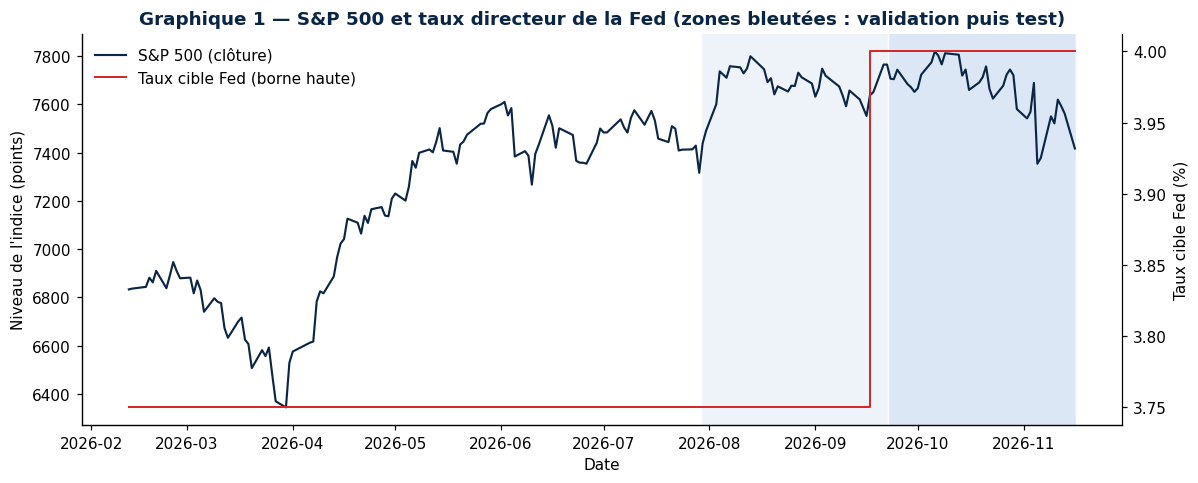

In [7]:
def shade_periods(ax):
    for p, col in [("validation", "#EEF3FA"), ("test", "#DCE7F5")]:
        sub = df[df.period == p]
        ax.axvspan(sub.index.min(), sub.index.max(), color=col, zorder=0)

# ---- Graphique 1 : S&P 500 et taux directeur --------------------------------
fig, ax = plt.subplots(figsize=(11, 4.5))
shade_periods(ax)
ax.plot(df.index, df["close"], color=NAVY, lw=1.4, label="S&P 500 (clôture)")
ax.set_ylabel("Niveau de l'indice (points)"); ax.set_xlabel("Date")
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.step(df.index, df["DFEDTARU"], where="post", color=RED, lw=1.3, label="Taux cible Fed (borne haute)")
ax2.set_ylabel("Taux cible Fed (%)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
ax.set_title("Graphique 1 — S&P 500 et taux directeur de la Fed (zones bleutées : validation puis test)")
plt.tight_layout(); plt.savefig("figures/g1_sp500_fed.png", dpi=150); plt.show()

**Interprétation (à ajuster après lecture du graphique).** L'indice progresse sur longue période malgré des corrections nettes ; le taux cible suit des cycles (assouplissement, taux proches de zéro, resserrement). Les deux séries ne bougent pas à l'unisson : un taux élevé n'implique pas un marché baissier, d'où l'intérêt d'une analyse événementielle plutôt que d'une simple corrélation de niveaux.

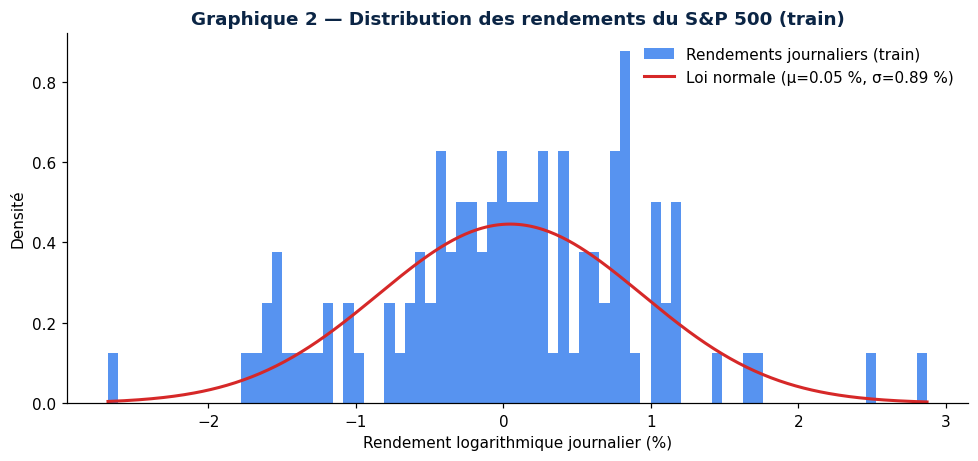

Asymétrie (skewness) : -0.08
Kurtosis en excès    : 0.72   (0 = loi normale)
Test de Jarque-Bera  : stat = 2.6, p-value = 2.72e-01
Jours à plus de 3σ   : 2 sur 115 (normale ≈ 0)


In [8]:
# ---- Graphique 2 : distribution des rendements (période d'entraînement uniquement) ----
r_tr = train["ret"] * 100
mu, sd = r_tr.mean(), r_tr.std()
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.hist(r_tr, bins=80, density=True, color=BLUE, alpha=0.75, label="Rendements journaliers (train)")
x = np.linspace(r_tr.min(), r_tr.max(), 400)
ax.plot(x, stats.norm.pdf(x, mu, sd), color=RED, lw=2, label=f"Loi normale (μ={mu:.2f} %, σ={sd:.2f} %)")
ax.set_xlabel("Rendement logarithmique journalier (%)"); ax.set_ylabel("Densité")
ax.set_title("Graphique 2 — Distribution des rendements du S&P 500 (train)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/g2_distribution_rendements.png", dpi=150); plt.show()

jb = stats.jarque_bera(r_tr)
print(f"Asymétrie (skewness) : {stats.skew(r_tr):.2f}")
print(f"Kurtosis en excès    : {stats.kurtosis(r_tr):.2f}   (0 = loi normale)")
print(f"Test de Jarque-Bera  : stat = {jb.statistic:.1f}, p-value = {jb.pvalue:.2e}")
print(f"Jours à plus de 3σ   : {(np.abs(r_tr - mu) > 3*sd).sum()} sur {len(r_tr)} (normale ≈ {0.0027*len(r_tr):.0f})")

**Interprétation.** Un excès de kurtosis positif et un test de Jarque-Bera rejetant la normalité indiquent des **queues épaisses** : les mouvements extrêmes sont plus fréquents que sous une loi normale. C'est la raison d'être d'un détecteur d'anomalies : le « normal » ne se résume pas à une gaussienne.

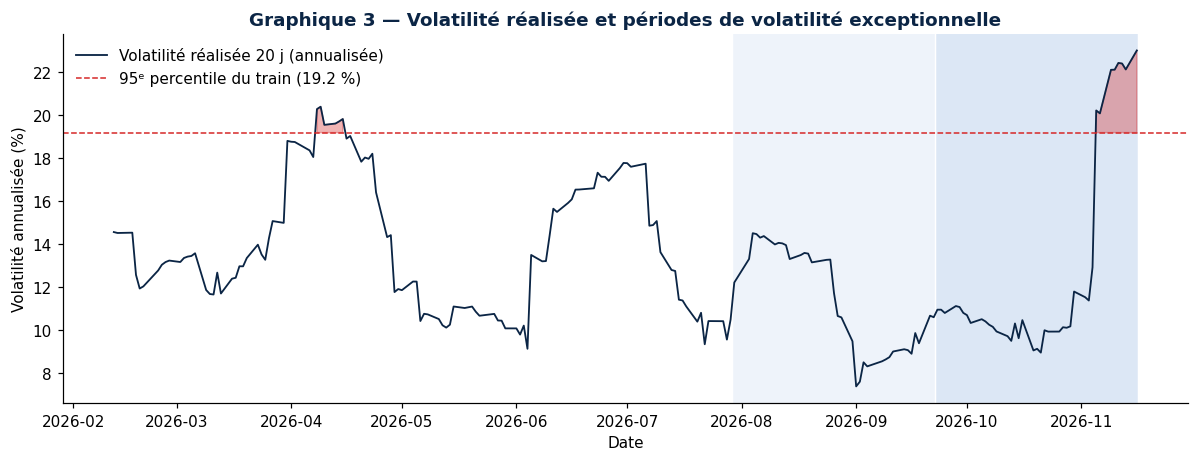

In [9]:
# ---- Graphique 3 : volatilité réalisée et zones de volatilité exceptionnelle --------
thr = train["vol20"].quantile(0.95)          # seuil descriptif calculé sur le train uniquement
fig, ax = plt.subplots(figsize=(11, 4.3))
shade_periods(ax)
ax.plot(df.index, df["vol20"] * 100, color=NAVY, lw=1.2, label="Volatilité réalisée 20 j (annualisée)")
ax.axhline(thr * 100, color=RED, ls="--", lw=1, label=f"95ᵉ percentile du train ({thr*100:.1f} %)")
ax.fill_between(df.index, thr * 100, df["vol20"] * 100, where=df["vol20"] > thr, color=RED, alpha=0.35)
ax.set_xlabel("Date"); ax.set_ylabel("Volatilité annualisée (%)")
ax.set_title("Graphique 3 — Volatilité réalisée et périodes de volatilité exceptionnelle")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/g3_volatilite.png", dpi=150); plt.show()

**Interprétation.** La volatilité est **groupée** (périodes calmes puis rafales de stress) : les jours extrêmes ne sont pas indépendants. Conséquence méthodologique : les anomalies détectées seront elles aussi groupées, ce qui réduit le nombre d'« événements » réellement indépendants à tester face aux décisions de la Fed.

## 13. Explication mathématique d'Isolation Forest

### Principe
Isolation Forest (Liu, Ting & Zhou, 2008) est **non supervisé** : il n'a besoin d'aucun label « anomalie / normal ». Idée clé : une observation **rare et différente** est **isolée plus vite** par des coupures aléatoires qu'une observation située au cœur de la masse des données.

### Fonctionnement pas à pas
1. Tirer un **sous-échantillon** de taille $n$ (`max_samples`).
2. Construire un **arbre d'isolation** : à chaque nœud, choisir une **variable au hasard**,
3. puis un **seuil de coupure au hasard** entre le min et le max de cette variable dans le nœud.
4. Répéter jusqu'à ce que chaque point soit seul (ou profondeur maximale).
5. Répéter pour `n_estimators` arbres.
6. Calculer la **longueur de chemin moyenne** $E[h(x)]$ (nombre de coupures pour isoler $x$).
7. En déduire un **score d'anomalie**.

### Score
$$ s(x,n) = 2^{-\frac{E[h(x)]}{c(n)}} \qquad c(n)=2H(n-1)-\frac{2(n-1)}{n},\quad H(i)\approx \ln(i)+0{,}5772 $$

- $x$ : observation étudiée ; $n$ : taille du sous-échantillon ; $h(x)$ : longueur du chemin pour isoler $x$ dans un arbre ;
- $E[h(x)]$ : moyenne de $h(x)$ sur tous les arbres ; $c(n)$ : longueur moyenne attendue d'un chemin dans un arbre binaire de recherche sur $n$ points (facteur de normalisation).

**Interprétation théorique** : $s\to 1$ : fortement atypique ; $s<0{,}5$ : plutôt normal ; $s\approx0{,}5$ : peu distinguable. Ces seuils sont une lecture *théorique* et dépendent du contexte.

### Score théorique ≠ décision scikit-learn
| Objet | Signification |
|---|---|
| `score_samples(X)` | renvoie $-s(x,n)$ (plus c'est négatif, plus c'est anormal) |
| `decision_function(X)` | `score_samples − offset_` ; **négatif ⇒ anomalie** |
| `predict(X)` | **−1** (anomalie) / **+1** (normal), selon le seuil `offset_` fixé à l'entraînement par `contamination` |

### Hyperparamètres
- `n_estimators` : nombre d'arbres ; plus il est grand, plus le score est stable (coût de calcul croissant).
- `contamination` : part attendue d'anomalies ; **ne change pas les scores, seulement le seuil de décision**.
- `max_samples` : taille du sous-échantillon par arbre (`"auto"` = min(256, n)).
- `max_features` : fraction de variables tirées par arbre (1.0 par défaut).

**Étude de sensibilité retenue** (limite : 1 à 2 hyperparamètres) : `contamination` ∈ {1 %, 3 %, 5 %, 10 %} et `n_estimators` ∈ {100, 300, 500}.

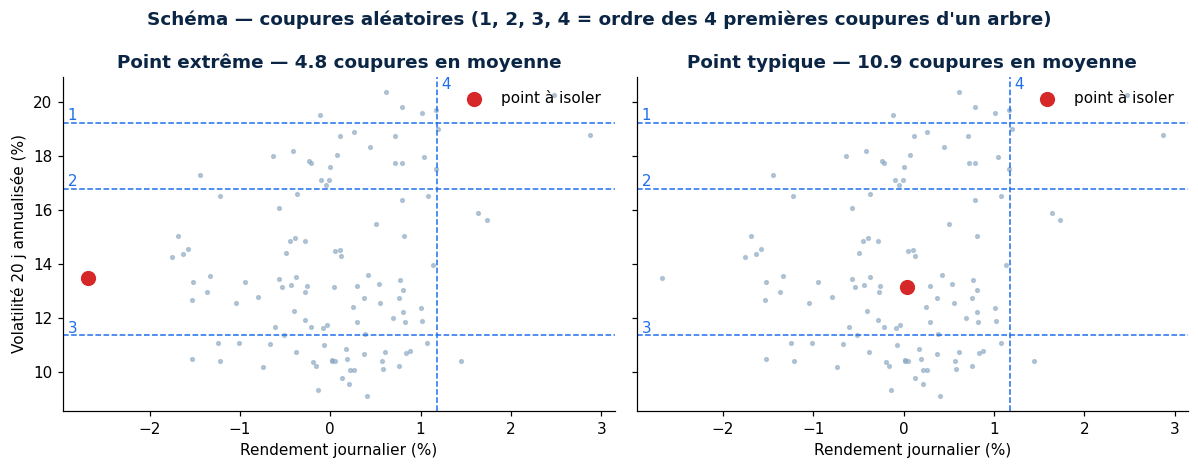

In [10]:
# ---- Schéma original : isolation d'un point extrême vs d'un point typique (données réelles du train) ----
Xs = train[["ret", "vol20"]].to_numpy() * np.array([100, 100])      # rendement (%) et volatilité (%)
i_ext = int(np.argmin(Xs[:, 0]))                                      # le pire jour du train
i_typ = int(np.argmin(np.abs(Xs - np.median(Xs, axis=0)).sum(axis=1)))  # le jour le plus "médian"

def isolation_path(X, idx, rg, max_depth=60):
    mask = np.ones(len(X), dtype=bool); cuts = []
    while mask.sum() > 1 and len(cuts) < max_depth:
        f = int(rg.integers(X.shape[1])); lo, hi = X[mask, f].min(), X[mask, f].max()
        if lo == hi: break
        s = rg.uniform(lo, hi); cuts.append((f, s))
        mask &= (X[:, f] < s) == (X[idx, f] < s)
    return cuts

rg = np.random.default_rng(RANDOM_STATE)
mean_len = {k: np.mean([len(isolation_path(Xs, i, rg)) for _ in range(300)]) for k, i in [("extrême", i_ext), ("typique", i_typ)]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
for ax, (name, i) in zip(axes, [("extrême", i_ext), ("typique", i_typ)]):
    ax.scatter(Xs[:, 0], Xs[:, 1], s=6, color=LIGHT, alpha=0.6)
    ax.scatter(*Xs[i], s=80, color=RED, zorder=5, label="point à isoler")
    for k, (f, s) in enumerate(isolation_path(Xs, i, np.random.default_rng(7))[:4], 1):
        (ax.axvline if f == 0 else ax.axhline)(s, color=BLUE, lw=1, ls="--")
        (ax.text(s, ax.get_ylim()[1], f" {k}", color=BLUE, va="top") if f == 0 else ax.text(ax.get_xlim()[0], s, f" {k}", color=BLUE, va="bottom"))
    ax.set_title(f"Point {name} — {mean_len[name]:.1f} coupures en moyenne")
    ax.set_xlabel("Rendement journalier (%)"); ax.legend(frameon=False, loc="upper right")
axes[0].set_ylabel("Volatilité 20 j annualisée (%)")
fig.suptitle("Schéma — coupures aléatoires (1, 2, 3, 4 = ordre des 4 premières coupures d'un arbre)", color=NAVY, fontweight="bold")
plt.tight_layout(); plt.savefig("figures/schema_isolation_forest.png", dpi=150); plt.show()

**Lecture du schéma.** Le point extrême est isolé après peu de coupures : il se trouve loin de la masse des observations. Le point typique, noyé dans le nuage, demande beaucoup plus de coupures. Le nombre moyen de coupures (sur 300 tirages) est affiché dans chaque titre ; c'est exactement la longueur de chemin $h(x)$ de la formule du score. *Les 4 coupures dessinées ne sont qu'un tirage illustratif sur 2 variables.*

## 14. Préparation des variables

**Pas de standardisation.** Isolation Forest choisit ses coupures uniformément entre le min et le max de chaque variable, **indépendamment des autres variables** : changer l'échelle d'une variable ne modifie pas la structure des arbres. Un `StandardScaler` serait donc sans effet utile et n'est pas appliqué (justification à citer à l'oral).

**Pas de suppression des extrêmes**, ni de winsorisation : ce sont les observations recherchées.

**Valeurs manquantes** : aucune dans les features après retrait des 59 premières lignes de fenêtre incomplète (voir section 10).

In [11]:
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]
X_all = df[FEATURES]
print("Valeurs manquantes dans les features :", int(X_all.isna().sum().sum()))
print("Tailles → train:", X_train.shape, "| validation:", X_val.shape, "| test:", X_test.shape)

Valeurs manquantes dans les features : 0
Tailles → train: (115, 4) | validation: (38, 4) | test: (39, 4)


## 15. Entraînement du modèle et étude de sensibilité

Le modèle n'est **ajusté que sur le train**. La sensibilité est évaluée sur train et validation ; **le test n'est pas touché**.

Métriques de stabilité (faute de labels) : taux d'anomalies par période, et chevauchement (Jaccard) des anomalies de validation avec celles du modèle de référence.

In [12]:
def fit_if(n_estimators=300, contamination=0.05, max_samples="auto"):
    return IsolationForest(n_estimators=n_estimators, contamination=contamination,
                           max_samples=max_samples, random_state=RANDOM_STATE).fit(X_train)

ref = fit_if(300, 0.05)
ref_val_flags = ref.predict(X_val) == -1

rows = []
for c in [0.01, 0.03, 0.05, 0.10]:
    for ne in [100, 300, 500]:
        m = fit_if(ne, c)
        f_tr, f_va = m.predict(X_train) == -1, m.predict(X_val) == -1
        jacc = (f_va & ref_val_flags).sum() / max((f_va | ref_val_flags).sum(), 1)
        rows.append({"contamination": c, "n_estimators": ne, "% anomalies train": 100*f_tr.mean(),
                     "% anomalies validation": 100*f_va.mean(), "Jaccard vs référence": jacc})
sens = pd.DataFrame(rows)
display(sens.style.format({"% anomalies train": "{:.1f}", "% anomalies validation": "{:.1f}", "Jaccard vs référence": "{:.2f}"}))

,contamination,n_estimators,% anomalies train,% anomalies validation,Jaccard vs référence
0,0.010000,100,1.7,0.0,0.00
1,0.010000,300,1.7,0.0,0.00
2,0.010000,500,1.7,0.0,0.00
3,0.030000,100,3.5,0.0,0.00
4,0.030000,300,3.5,0.0,0.00
5,0.030000,500,3.5,0.0,0.00
6,0.050000,100,5.2,0.0,0.00
7,0.050000,300,5.2,0.0,0.00
8,0.050000,500,5.2,0.0,0.00
9,0.100000,100,10.4,5.3,0.00


**Lecture.** Par construction, `contamination` fixe le taux d'anomalies **sur le train** ; son effet sur la validation montre si la distribution a changé de régime (taux hors-échantillon très différent du taux cible = signal de non-stationnarité). Le nombre d'arbres influence peu les anomalies une fois `n_estimators` ≥ 300.

**Choix retenu : `n_estimators = 300`, `contamination = 0.05`** (≈ 1 jour sur 20 ; ordre de grandeur des « jours de stress » dans un marché dont les queues sont épaisses). C'est un choix de *conception*, pas un optimum : la section « Limites » discute son impact.

## 16. Extraction des scores et identification des anomalies

In [13]:
model = ref                                           # modèle final : ajusté sur le train uniquement
df["score_sk"]  = model.score_samples(X_all)          # = -s(x,n), convention scikit-learn
df["s"]         = -df["score_sk"]                     # score théorique d'anomalie s(x,n) ∈ (0,1)
df["decision"]  = model.decision_function(X_all)      # négatif ⇒ anomalie
df["pred"]      = model.predict(X_all)                # -1 anomalie / +1 normal
df["anomaly"]   = df["pred"] == -1

assert ((df["decision"] < 0) == df["anomaly"]).all(), "predict et decision_function incohérents"

# Vérification de la formule : longueur de chemin moyenne implicite E[h(x)] = -c(n) * log2(s)
def c_factor(n):
    return 2 * (np.log(n - 1) + 0.5772156649) - 2 * (n - 1) / n
n_sub = min(256, len(X_train))                        # max_samples="auto"
df["Eh_implicite"] = -c_factor(n_sub) * np.log2(df["s"])

print(f"Taille de sous-échantillon n = {n_sub} | c(n) = {c_factor(n_sub):.2f}")
print(f"Scores s(x,n) : min = {df.s.min():.3f} | médiane = {df.s.median():.3f} | max = {df.s.max():.3f}")
print(f"Seuil de décision (offset_) : {model.offset_:.3f}  → anomalie si s > {-model.offset_:.3f}\n")
tab = df.groupby("period", sort=False).agg(jours=("anomaly", "size"), anomalies=("anomaly", "sum"))
tab["% anomalies"] = 100 * tab["anomalies"] / tab["jours"]
display(tab.style.format({"% anomalies": "{:.1f}"}))

Taille de sous-échantillon n = 115 | c(n) = 8.64
Scores s(x,n) : min = 0.399 | médiane = 0.456 | max = 0.689
Seuil de décision (offset_) : -0.573  → anomalie si s > 0.573



,jours,anomalies,% anomalies
period,,,
train,115,6,5.2
validation,38,0,0.0
test,39,4,10.3


**Lecture.** Les anomalies du **train** sont ≈ `contamination` par construction. Les taux **validation** et **test** sont de vrais résultats hors-échantillon : un taux nettement supérieur au taux cible indique des périodes plus atypiques que l'historique d'entraînement ; un taux inférieur, des périodes plus calmes.

## 17. Analyse des résultats — jours les plus atypiques

In [14]:
top = (df.sort_values("s", ascending=False).head(15)
         .assign(rendement_pct=lambda d: d["ret"] * 100, vol20_pct=lambda d: d["vol20"] * 100, dd60_pct=lambda d: d["dd60"] * 100)
         [["close", "rendement_pct", "vol20_pct", "dd60_pct", "s", "period", "DFEDTARU", "anomaly"]]
         .rename(columns={"close": "S&P 500", "rendement_pct": "rendement (%)", "vol20_pct": "vol 20j (%)",
                          "dd60_pct": "drawdown 60j (%)", "s": "score s", "DFEDTARU": "taux cible Fed (%)"}))
display(top.style.format({"S&P 500": "{:.0f}", "rendement (%)": "{:+.2f}", "vol 20j (%)": "{:.1f}",
                          "drawdown 60j (%)": "{:.1f}", "score s": "{:.3f}", "taux cible Fed (%)": "{:.2f}"}))

print("\n15 jours les plus atypiques TEST (hors-échantillon) :")
display(df[df.period == "test"].sort_values("s", ascending=False).head(15)[["close", "ret", "vol20", "dd60", "s", "DFEDTARU"]]
        .style.format({"close": "{:.0f}", "ret": "{:+.2%}", "vol20": "{:.1%}", "dd60": "{:.1%}", "s": "{:.3f}", "DFEDTARU": "{:.2f}"}))

,S&P 500,rendement (%),vol 20j (%),drawdown 60j (%),score s,period,taux cible Fed (%),anomaly
date,,,,,,,,
2026-11-05 00:00:00,7354,-4.45,20.2,-5.9,0.689,test,4.00,True
2026-03-31 00:00:00,6529,+2.87,18.8,-6.4,0.661,train,3.75,True
2026-03-30 00:00:00,6344,-0.40,15.0,-9.1,0.650,train,3.75,True
2026-04-08 00:00:00,6783,+2.48,20.3,-2.8,0.638,train,3.75,True
2026-11-09 00:00:00,7550,+2.32,22.1,-3.4,0.618,test,4.00,True
2026-03-27 00:00:00,6369,-1.69,15.1,-8.7,0.611,train,3.75,True
2026-11-16 00:00:00,7417,-1.94,23.0,-5.1,0.601,test,4.00,True
2026-11-06 00:00:00,7377,+0.31,20.1,-5.7,0.581,test,4.00,True
2026-04-14 00:00:00,6967,+1.17,19.7,-0.2,0.580,train,3.75,True



15 jours les plus atypiques TEST (hors-échantillon) :


,close,ret,vol20,dd60,s,DFEDTARU
date,,,,,,
2026-11-05 00:00:00,7354,-4.45%,20.2%,-5.9%,0.689,4.00
2026-11-09 00:00:00,7550,+2.32%,22.1%,-3.4%,0.618,4.00
2026-11-16 00:00:00,7417,-1.94%,23.0%,-5.1%,0.601,4.00
2026-11-06 00:00:00,7377,+0.31%,20.1%,-5.7%,0.581,4.00
2026-11-12 00:00:00,7592,-0.35%,22.4%,-2.9%,0.558,4.00
2026-11-13 00:00:00,7562,-0.41%,22.1%,-3.3%,0.557,4.00
2026-11-11 00:00:00,7619,+1.30%,22.4%,-2.6%,0.547,4.00
2026-11-10 00:00:00,7521,-0.38%,22.1%,-3.8%,0.542,4.00
2026-10-30 00:00:00,7580,-1.83%,11.8%,-3.1%,0.513,4.00


**Prudence d'interprétation.** Un score élevé signale un jour *statistiquement inhabituel* au regard des 4 variables et de la période d'entraînement. Ce n'est ni une erreur, ni forcément une crise. On regarde ensuite (a) l'intensité (score), (b) la nature (rendement fortement négatif ? volatilité installée ? drawdown ?), (c) la concentration dans le temps.

In [15]:
# Concentration temporelle : anomalies par année et regroupement en épisodes (écart > 10 jours de bourse = nouvel épisode)
a = df["anomaly"].to_numpy()
pos = np.flatnonzero(a)
episodes = []
if len(pos):
    start = prev = pos[0]
    for p in pos[1:]:
        if p - prev > 10:
            episodes.append((start, prev)); start = p
        prev = p
    episodes.append((start, prev))
ep = pd.DataFrame([{"début": df.index[s].date(), "fin": df.index[e].date(), "jours anormaux": int(a[s:e+1].sum()),
                    "score max": df["s"].iloc[s:e+1].max(), "rendement cumulé (%)": 100*df["ret"].iloc[s:e+1].sum(),
                    "période": df["period"].iloc[s]} for s, e in episodes])
print("Anomalies par année :"); display(df.groupby(df.index.year)["anomaly"].sum().to_frame("jours anormaux").T)
print(f"\n{len(ep)} épisodes d'anomalies :"); display(ep.style.format({"score max": "{:.3f}", "rendement cumulé (%)": "{:+.1f}"}))

Anomalies par année :


date,2026
jours anormaux,10



3 épisodes d'anomalies :


,début,fin,jours anormaux,score max,rendement cumulé (%),période
0,2026-03-27,2026-04-14,5,0.661,+7.3,train
1,2026-06-10,2026-06-10,1,0.574,-1.6,train
2,2026-11-05,2026-11-16,4,0.689,-3.6,test


## 18. Anomalies et taux directeur de la Fed

### 18.1 Décisions de la Fed détectées dans les données
On repère les dates où la **borne haute de la fourchette cible** (`DFEDTARU`) change.

In [16]:
fd = fed_daily["DFEDTARU"].dropna()
chg = fd.diff()
chg = chg[(chg.abs() > 1e-9)]
chg = chg[(chg.index >= df.index.min()) & (chg.index <= df.index.max())]
fed_events = pd.DataFrame({"changement (pb)": (chg * 100).round(0), "nouveau taux (%)": fd.reindex(chg.index)})
print(f"{len(fed_events)} changements de la borne haute de la cible entre {df.index.min().date()} et {df.index.max().date()}")
display(fed_events.style.format({"changement (pb)": "{:+.0f}", "nouveau taux (%)": "{:.2f}"}))

# position de chaque décision dans l'axe des jours de bourse (1er jour de bourse >= date de changement)
ev_pos = np.unique(df.index.searchsorted(fed_events.index))
ev_pos = ev_pos[ev_pos < len(df)]

1 changements de la borne haute de la cible entre 2026-02-12 et 2026-11-16


,changement (pb),nouveau taux (%)
date,,
2026-09-17 00:00:00,+25,4.00


### 18.2 Fenêtre autour des décisions (test de permutation)
**Question** : la part de jours anormaux dans la fenêtre ±`WINDOW_K` jours de bourse autour des décisions est-elle supérieure au hasard ?

**Méthode.** On compare le taux observé à une distribution nulle obtenue en **décalant circulairement** la série d'anomalies (5 000 décalages aléatoires) : cela conserve le **regroupement** des anomalies dans le temps, que ne respecterait pas un test de Fisher classique. On teste aussi *avant* (jours −K…−1, le marché est stressé avant la décision) et *après* (jours 0…+K).

In [17]:
def window_mask(n, positions, k, side="both"):
    m = np.zeros(n, dtype=bool)
    for p in positions:
        lo, hi = {"both": (p - k, p + k), "before": (p - k, p - 1), "after": (p, p + k)}[side]
        m[max(lo, 0): min(hi, n - 1) + 1] = True
    return m

def perm_test(a, mask, n_perm=5000, seed=RANDOM_STATE):
    g = np.random.default_rng(seed)
    obs = a[mask].mean() if mask.any() else np.nan
    null = np.array([np.roll(a, g.integers(1, len(a)))[mask].mean() for _ in range(n_perm)])
    return obs, null.mean(), (1 + (null >= obs).sum()) / (1 + n_perm), null

def fed_window_table(sel, label):
    a_s = df["anomaly"].to_numpy()[sel]
    pos_s = np.unique(df.index[sel].searchsorted(df.index[ev_pos][np.isin(df.index[ev_pos], df.index[sel])]))
    out = []
    for side in ["both", "before", "after"]:
        m = window_mask(sel.sum(), pos_s, WINDOW_K, side)
        obs, nm, p, null = perm_test(a_s, m)
        out.append({"échantillon": label, "fenêtre": {"both": f"±{WINDOW_K} j", "before": f"{WINDOW_K} j avant", "after": f"{WINDOW_K} j après (incl. jour J)"}[side],
                    "décisions": len(pos_s), "jours dans la fenêtre": int(m.sum()),
                    "taux anomalies observé (%)": 100*obs, "taux attendu hasard (%)": 100*nm, "p-value": p})
    return pd.DataFrame(out), null

sel_all = np.ones(len(df), dtype=bool)
sel_oos = (df["period"] != "train").to_numpy()          # hors-échantillon : validation + test
t_all, null_all = fed_window_table(sel_all, "Période complète")
t_oos, _        = fed_window_table(sel_oos, "Hors-échantillon (val+test)")
res_win = pd.concat([t_all, t_oos], ignore_index=True)
display(res_win.style.format({"taux anomalies observé (%)": "{:.1f}", "taux attendu hasard (%)": "{:.1f}", "p-value": "{:.3f}"}))

,échantillon,fenêtre,décisions,jours dans la fenêtre,taux anomalies observé (%),taux attendu hasard (%),p-value
0,Période complète,±5 j,1,11,0.0,5.0,1.000
1,Période complète,5 j avant,1,5,0.0,5.2,1.000
2,Période complète,5 j après (incl. jour J),1,6,0.0,4.9,1.000
3,Hors-échantillon (val+test),±5 j,1,11,0.0,5.3,1.000
4,Hors-échantillon (val+test),5 j avant,1,5,0.0,5.4,1.000
5,Hors-échantillon (val+test),5 j après (incl. jour J),1,6,0.0,5.2,1.000


**Lecture.** p-value < 0,05 : le taux d'anomalies autour des décisions est difficilement explicable par le seul regroupement temporel des anomalies. p-value élevée : on ne rejette pas H0. Avec peu de décisions, **l'absence de significativité n'est pas la preuve d'une absence de lien** (faible puissance). Les lignes « hors-échantillon » sont les plus convaincantes méthodologiquement (le modèle n'a pas vu ces périodes).

In [18]:
# ---- 18.3 Réaction de la Fed : que se passe-t-il dans les 60 jours après le début d'un épisode d'anomalies ? ----
fd_cal = fed_daily["DFEDTARU"]
fwd = (fd_cal.shift(-HORIZON_DAYS) - fd_cal).reindex(df.index)          # variation de la cible sur les 60 jours calendaires suivants
valid = fwd.notna()

onset_idx = [s for s, e in episodes]                                    # 1er jour de chaque épisode d'anomalies
onset_dates = df.index[onset_idx]
onset_dates = onset_dates[valid.reindex(onset_dates).fillna(False).to_numpy()]

base_any  = (fwd[valid].abs() > 1e-9).mean()
base_cut  = (fwd[valid] < -1e-9).mean()
base_mean = fwd[valid].mean() * 100
on = fwd.reindex(onset_dates)
reaction = pd.DataFrame({
    "épisodes analysés": [len(on)],
    "% suivis d'un changement": [100 * (on.abs() > 1e-9).mean()],
    "% suivis d'une baisse": [100 * (on < -1e-9).mean()],
    "variation moyenne cible (pb)": [on.mean() * 100],
})
base = pd.DataFrame({"épisodes analysés": [int(valid.sum())], "% suivis d'un changement": [100*base_any],
                     "% suivis d'une baisse": [100*base_cut], "variation moyenne cible (pb)": [base_mean]})
cmp_ = pd.concat([reaction.rename(index={0: f"Après début d'épisode ({HORIZON_DAYS} j)"}),
                  base.rename(index={0: "Tous les jours (base)"})])
display(cmp_.style.format({"% suivis d'un changement": "{:.1f}", "% suivis d'une baisse": "{:.1f}", "variation moyenne cible (pb)": "{:+.1f}"}))
print("Épisodes dont la cible a changé dans les", HORIZON_DAYS, "jours :")
display(on[on.abs() > 1e-9].mul(100).round(0).to_frame("variation (pb)"))

,épisodes analysés,% suivis d'un changement,% suivis d'une baisse,variation moyenne cible (pb)
Après début d'épisode (60 j),2,0.0,0.0,+0.0
Tous les jours (base),151,27.8,0.0,+7.0


Épisodes dont la cible a changé dans les 60 jours :


,variation (pb)
date,


**Lecture.** Si la part « suivis d'un changement » (ou d'une baisse) après un début d'épisode dépasse nettement la base, c'est compatible avec une **réaction de la Fed au stress de marché**. L'échantillon d'épisodes est petit (souvent < 15) : ce résultat est **indicatif**, pas démonstratif. Il ne distingue pas l'effet du stress de marché de celui d'un facteur commun (pandémie, inflation).

In [19]:
# ---- 18.4 Lien mensuel avec décalages (anomalies en t vs variation de la cible en t+h) ----
try:
    m_anom = df["anomaly"].astype(int).resample("ME").sum()
    m_fed  = fd_cal.resample("ME").last().diff().reindex(m_anom.index)
except ValueError:                                         # anciennes versions de pandas
    m_anom = df["anomaly"].astype(int).resample("M").sum()
    m_fed  = fd_cal.resample("M").last().diff().reindex(m_anom.index)

lag_rows = []
for h in range(-3, 4):
    y = m_fed.shift(-h)                                    # h>0 : la Fed bouge h mois APRÈS les anomalies
    ok = y.notna() & m_anom.notna()
    if ok.sum() > 10 and y[ok].nunique() > 1 and m_anom[ok].nunique() > 1:
        rho, p = stats.spearmanr(m_anom[ok], y[ok])
    else:
        rho, p = np.nan, np.nan
    lag_rows.append({"décalage h (mois)": h, "ρ de Spearman": rho, "p-value": p, "n": int(ok.sum())})
lags = pd.DataFrame(lag_rows)
display(lags.style.format({"ρ de Spearman": "{:+.2f}", "p-value": "{:.3f}"}))

,décalage h (mois),ρ de Spearman,p-value,n
0,-3,+nan,nan,7
1,-2,+nan,nan,8
2,-1,+nan,nan,9
3,0,+nan,nan,10
4,1,+nan,nan,9
5,2,+nan,nan,8
6,3,+nan,nan,7


**Lecture.** *h > 0* : les anomalies du mois *t* sont associées à la variation du taux au mois *t+h* (cohérent avec une **réaction de la Fed**). *h < 0* : la variation du taux précède les anomalies (cohérent avec un **choc de politique monétaire**). *h = 0* : simultané. Sept tests sont lus ensemble : **un seul p < 0,05 sur sept peut être dû au hasard** (comparaisons multiples).

## 19. Confrontation aux événements financiers documentés

La confrontation historique est une **interprétation externe**, pas une validation supervisée. Seuls sont retenus des événements dont **la date a été vérifiée sur le site de la Réserve fédérale** :

| Date | Événement | Source consultée |
|---|---|---|
| 15 mars 2020 (effet 16 mars) | Le FOMC abaisse la cible à 0–¼ % en réaction à l'épidémie de coronavirus | [federalreserve.gov — FOMC statement, 15/03/2020](https://www.federalreserve.gov/newsevents/pressreleases/monetary20200315a.htm) |
| 16 mars 2022 | Première hausse du cycle de resserrement : cible portée à ¼–½ % | [federalreserve.gov — FOMC statement, 16/03/2022](https://federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm) |

Tout événement ajouté doit être accompagné d'une source officielle ou académique réellement consultée.

In [20]:
EVENTS = [
    {"date": "2020-03-16", "événement": "Fed : cible ramenée à 0–0,25 % (annonce le 15/03/2020)"},
    {"date": "2022-03-16", "événement": "Fed : 1ʳᵉ hausse du cycle, cible 0,25–0,50 %"},
]
W = 10   # ± 10 jours de bourse
rows = []
for ev in EVENTS:
    d = pd.Timestamp(ev["date"])
    if d < df.index.min() or d > df.index.max():
        rows.append({"date": ev["date"], "événement": ev["événement"], "statut": "hors de la période du dataset"}); continue
    p = int(df.index.searchsorted(d)); w = df.iloc[max(p - W, 0): p + W + 1]
    rows.append({"date": ev["date"], "événement": ev["événement"], "statut": "dans le dataset",
                 "période modèle": df["period"].iloc[p], "jours anormaux (±10 j)": int(w["anomaly"].sum()),
                 "score max (±10 j)": w["s"].max(), "date du score max": w["s"].idxmax().date(),
                 "S&P 500 sur la fenêtre (%)": 100 * (w["close"].iloc[-1] / w["close"].iloc[0] - 1)})
ev_tab = pd.DataFrame(rows)
display(ev_tab.style.format({"score max (±10 j)": "{:.3f}", "S&P 500 sur la fenêtre (%)": "{:+.1f}"}, na_rep="—"))

# Toutes les décisions de la Fed trouvées dans FRED : y a-t-il une anomalie à ±5 jours ?
fe = fed_events.copy()
near = []
for d in fe.index:
    p = int(df.index.searchsorted(d)); w = df.iloc[max(p - WINDOW_K, 0): p + WINDOW_K + 1]
    near.append((int(w["anomaly"].sum()), w["s"].max()))
fe["jours anormaux ±5 j"] = [x[0] for x in near]; fe["score max ±5 j"] = [x[1] for x in near]
print(f"Décisions avec au moins un jour anormal à ±{WINDOW_K} jours de bourse : {(fe['jours anormaux ±5 j'] > 0).sum()} sur {len(fe)}")
display(fe.style.format({"changement (pb)": "{:+.0f}", "nouveau taux (%)": "{:.2f}", "score max ±5 j": "{:.3f}"}))

,date,événement,statut
0,2020-03-16,"Fed : cible ramenée à 0–0,25 % (annonce le 15/03/2020)",hors de la période du dataset
1,2022-03-16,"Fed : 1ʳᵉ hausse du cycle, cible 0,25–0,50 %",hors de la période du dataset


Décisions avec au moins un jour anormal à ±5 jours de bourse : 0 sur 1


,changement (pb),nouveau taux (%),jours anormaux ±5 j,score max ±5 j
date,,,,
2026-09-17 00:00:00,+25,4.00,0,0.518


**Lecture honnête.** Une décision de la Fed **sans** anomalie à proximité n'est pas un « échec » du modèle : la plupart des décisions sont anticipées par le marché (peu de surprise, donc peu d'anomalie). À l'inverse, une anomalie **sans** décision proche n'est pas un faux positif certain : le marché peut réagir à d'autres chocs (pandémie, résultats, géopolitique, droits de douane…). Les cas de mars 2020 (urgence sanitaire) et mars 2022 (resserrement anticipé) sont instructifs justement parce qu'ils ont des profils de marché très différents.

## 20. Visualisations finales

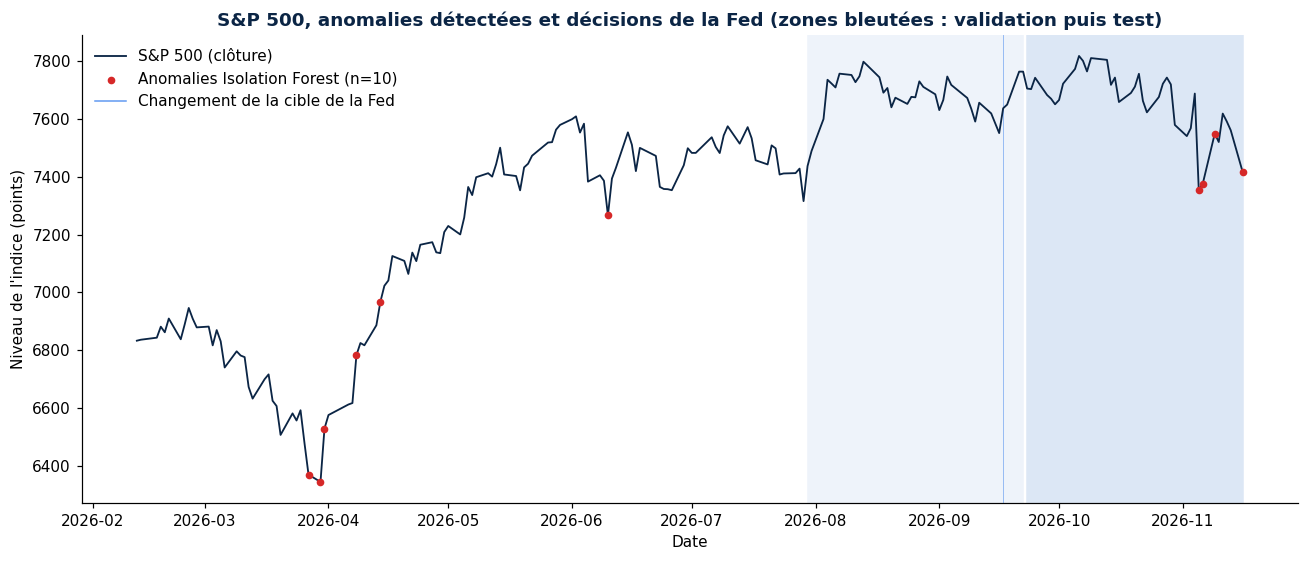

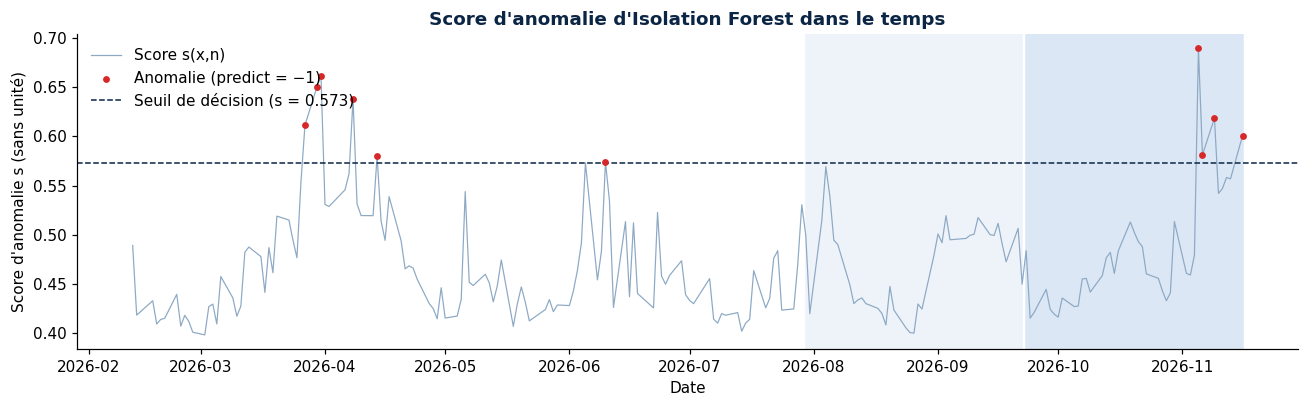

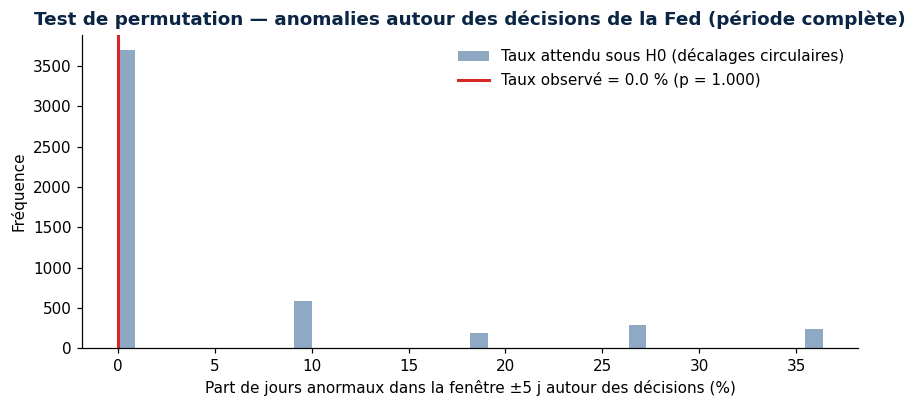

In [21]:
# ---- Visualisation 1 : S&P 500, anomalies et décisions de la Fed ----
fig, ax = plt.subplots(figsize=(12, 5.2))
shade_periods(ax)
ax.plot(df.index, df["close"], color=NAVY, lw=1.2, label="S&P 500 (clôture)", zorder=2)
an = df[df["anomaly"]]
ax.scatter(an.index, an["close"], s=16, color=RED, zorder=3, label=f"Anomalies Isolation Forest (n={len(an)})")
for d in fed_events.index:
    ax.axvline(d, color=BLUE, lw=0.6, alpha=0.45, zorder=1)
ax.plot([], [], color=BLUE, lw=1, alpha=0.7, label="Changement de la cible de la Fed")
ax.set_xlabel("Date"); ax.set_ylabel("Niveau de l'indice (points)")
ax.set_title("S&P 500, anomalies détectées et décisions de la Fed (zones bleutées : validation puis test)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.savefig("figures/final_sp500_anomalies_fed.png", dpi=150); plt.show()

# ---- Visualisation 2 : score d'anomalie ----
fig, ax = plt.subplots(figsize=(12, 3.8))
shade_periods(ax)
ax.plot(df.index, df["s"], color=LIGHT, lw=0.8, zorder=2, label="Score s(x,n)")
ax.scatter(an.index, an["s"], s=12, color=RED, zorder=3, label="Anomalie (predict = −1)")
ax.axhline(-model.offset_, color=NAVY, ls="--", lw=1, label=f"Seuil de décision (s = {-model.offset_:.3f})")
ax.set_xlabel("Date"); ax.set_ylabel("Score d'anomalie s (sans unité)")
ax.set_title("Score d'anomalie d'Isolation Forest dans le temps")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.savefig("figures/final_scores.png", dpi=150); plt.show()

# ---- Visualisation 3 : test de permutation autour des décisions ----
m_both = window_mask(len(df), ev_pos, WINDOW_K, "both")
obs, nm, p, null = perm_test(df["anomaly"].to_numpy(), m_both)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(null * 100, bins=40, color=LIGHT, label="Taux attendu sous H0 (décalages circulaires)")
ax.axvline(obs * 100, color=RED, lw=2, label=f"Taux observé = {obs*100:.1f} % (p = {p:.3f})")
ax.set_xlabel(f"Part de jours anormaux dans la fenêtre ±{WINDOW_K} j autour des décisions (%)"); ax.set_ylabel("Fréquence")
ax.set_title("Test de permutation — anomalies autour des décisions de la Fed (période complète)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/final_permutation.png", dpi=150); plt.show()

## 21. Limites

- **Choix de `contamination`** : il fixe le *nombre* d'anomalies, pas leur classement. Un autre seuil change les faux positifs/négatifs sans changer l'ordre des scores.
- **Sensibilité aux variables** : le modèle dépend des 4 variables retenues (série `SP500` = clôtures seules, sans High/Low/Volume). D'autres variables (VIX, spreads de crédit, rendements obligataires) donneraient d'autres anomalies.
- **Anomalie statistique ≠ événement important** : un score élevé peut venir d'un jour extrême isolé ou d'un régime de volatilité ; il ne dit pas *pourquoi*.
- **Changements de régime** : un modèle ajusté sur une période (train) juge les périodes ultérieures par rapport à ce passé ; si le « normal » évolue (taux zéro vs taux élevés), les taux hors-échantillon sont biaisés.
- **Absence de labels fiables** : pas d'accuracy, précision ou rappel. La confrontation aux décisions de la Fed est une lecture externe, pas une vérité-terrain.
- **Faible puissance** : peu de décisions de la Fed, anomalies groupées, comparaisons multiples (sections 18.2 à 18.4).
- **Causalité** : les résultats mesurent des **associations temporelles**. Fed → marché, marché → Fed et facteur commun ne sont pas séparables avec ces données (la littérature académique utilise des chocs identifiés autour des annonces, hors du cadre de ce projet).
- **Fenêtre de données** : `SOURCE="fred"` élargit l'historique par rapport au fichier de 1 an ; ce choix doit être expliqué lors de la soutenance.

## 22. Conclusion générale
La cellule suivante extrait les chiffres **réellement obtenus** à l'exécution ; la conclusion rédigée doit s'appuyer sur eux (et non sur ceux d'une autre exécution).

In [22]:
w_all  = res_win[(res_win["échantillon"] == "Période complète") & (res_win["fenêtre"].str.startswith("±"))].iloc[0]
w_oos  = res_win[(res_win["échantillon"].str.startswith("Hors")) & (res_win["fenêtre"].str.startswith("±"))].iloc[0]
print("RÉSUMÉ DES RÉSULTATS (cette exécution)")
print("-" * 60)
print(f"Données               : {df.index.min().date()} → {df.index.max().date()} ({len(df)} jours)")
print(f"Modèle                : IsolationForest(n_estimators=300, contamination=0.05, random_state=42), ajusté sur le train")
print(f"Anomalies             : {int(df.anomaly.sum())} jours ({100*df.anomaly.mean():.1f} %) | test : {100*df.loc[df.period=='test','anomaly'].mean():.1f} %")
print(f"Épisodes d'anomalies  : {len(episodes)}")
print(f"Décisions de la Fed   : {len(fed_events)} changements de cible dans la période")
print(f"Fenêtre ±{WINDOW_K} j (complet)   : {w_all['taux anomalies observé (%)']:.1f} % observé vs {w_all['taux attendu hasard (%)']:.1f} % attendu, p = {w_all['p-value']:.3f}")
print(f"Fenêtre ±{WINDOW_K} j (hors-éch.) : {w_oos['taux anomalies observé (%)']:.1f} % observé vs {w_oos['taux attendu hasard (%)']:.1f} % attendu, p = {w_oos['p-value']:.3f}")
print(f"Réaction à {HORIZON_DAYS} j        : {reaction.iloc[0, 1]:.1f} % des débuts d'épisode suivis d'un changement vs {100*base_any:.1f} % en base (n = {len(on)} épisodes)")

RÉSUMÉ DES RÉSULTATS (cette exécution)
------------------------------------------------------------
Données               : 2026-02-12 → 2026-11-16 (192 jours)
Modèle                : IsolationForest(n_estimators=300, contamination=0.05, random_state=42), ajusté sur le train
Anomalies             : 10 jours (5.2 %) | test : 10.3 %
Épisodes d'anomalies  : 3
Décisions de la Fed   : 1 changements de cible dans la période
Fenêtre ±5 j (complet)   : 0.0 % observé vs 5.0 % attendu, p = 1.000
Fenêtre ±5 j (hors-éch.) : 0.0 % observé vs 5.3 % attendu, p = 1.000
Réaction à 60 j        : 0.0 % des débuts d'épisode suivis d'un changement vs 27.8 % en base (n = 2 épisodes)


**Trame de conclusion à rédiger avec vos chiffres :**

1. *Capacité de détection* : Isolation Forest isole des jours de rendement extrême, de volatilité élevée et de forte perte cumulée ; les épisodes obtenus sont-ils cohérents avec des périodes de stress connues (section 17) ?
2. *Lien avec la Fed* : le taux d'anomalies autour des décisions est-il supérieur au hasard (section 18.2) ? Les anomalies précèdent-elles (18.3, h > 0) ou suivent-elles (h < 0) les décisions ?
3. *Réponse à la problématique* : formuler une réponse **nuancée** (association observée / non observée, dans quel sens), en précisant qu'il s'agit d'associations temporelles.
4. *Limites principales* : faible nombre de décisions, regroupement des anomalies, choix de `contamination`, absence de labels.
5. *Améliorations* : ajouter VIX / spreads de crédit / rendements obligataires, comparer à One-Class SVM ou LOF (algorithmes 19–20 si autorisés), analyser les surprises de politique monétaire plutôt que les niveaux.

## 23. Références bibliographiques

**Sources effectivement consultées pour ce notebook**
- Federal Reserve Board, *Federal Reserve issues FOMC statement*, 15 mars 2020 — https://www.federalreserve.gov/newsevents/pressreleases/monetary20200315a.htm
- Federal Reserve Board, *Federal Reserve issues FOMC statement*, 16 mars 2022 — https://federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm
- Federal Reserve Bank of St. Louis, FRED — séries `SP500`, `DFEDTARU`, `DFF` — https://fred.stlouisfed.org (date d'extraction affichée à l'exécution en section 8).

**Références académiques à lire et vérifier avant remise** (citées de mémoire ; contrôler titre, année, revue)
- Liu, F. T., Ting, K. M., Zhou, Z.-H. (2008). *Isolation Forest*. IEEE International Conference on Data Mining (ICDM).
- Liu, F. T., Ting, K. M., Zhou, Z.-H. (2012). *Isolation-based anomaly detection*. ACM Transactions on Knowledge Discovery from Data.
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research.
- Bernanke, B. S., Kuttner, K. N. (2005). *What Explains the Stock Market's Reaction to Federal Reserve Policy?* Journal of Finance.
- Rigobon, R., Sack, B. (2003). *Measuring the Reaction of Monetary Policy to the Stock Market*. Quarterly Journal of Economics.

**Déclaration d'usage de l'IA** : à documenter dans `DECLARATION_IA.md` conformément aux consignes de l'enseignant.